# Retail Sales Analytics — Exploratory Data Analysis
**Tech stack:** Python, NumPy, Pandas, Matplotlib, Seaborn

This notebook analyzes two years (2023–2024) of synthetic e-commerce retail sales data across
5 categories, 11 cities, and 4 regions of India. It covers data cleaning, feature engineering,
exploratory analysis, and visualization — the full workflow of a real-world analytics project.

**Sections:**
1. Load & Inspect Data
2. Data Cleaning
3. Feature Engineering
4. Exploratory Data Analysis (EDA)
5. Visualizations
6. Key Business Insights


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

## 1. Load & Inspect Data

In [2]:
df = pd.read_csv("../data/retail_sales.csv", parse_dates=["order_date"])
print("Shape:", df.shape)
df.head()

Shape: (8015, 13)


,order_id,order_date,category,product,city,region,quantity,unit_price,discount_pct,revenue,payment_mode,customer_segment,customer_rating
0,ORD105700,2024-08-29,Electronics,Smartphone,Hyderabad,South,3,17230.03,5,49105.58,Net Banking,New,4.4
1,ORD102344,2023-01-07,Electronics,Headphones,Hyderabad,South,1,2005.70,5,1905.41,Credit Card,Returning,3.6
2,ORD107882,2023-12-17,Electronics,Tablet,Hyderabad,South,1,15484.18,20,14864.81,Net Banking,Loyal,4.2
3,ORD107902,2023-02-15,Beauty,Lipstick,Kolkata,East,1,416.80,0,416.80,Net Banking,Loyal,3.7
4,ORD105315,2024-09-16,Beauty,Sunscreen,Lucknow,North,1,387.37,0,387.37,UPI,Loyal,4.8


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          8015 non-null   str           
 1   order_date        8015 non-null   datetime64[us]
 2   category          8015 non-null   str           
 3   product           8015 non-null   str           
 4   city              8015 non-null   str           
 5   region            8015 non-null   str           
 6   quantity          8015 non-null   int64         
 7   unit_price        8015 non-null   float64       
 8   discount_pct      8015 non-null   int64         
 9   revenue           8015 non-null   float64       
 10  payment_mode      8015 non-null   str           
 11  customer_segment  8015 non-null   str           
 12  customer_rating   7855 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(7)
memory usage: 814.2 KB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,8015,8000,ORD102555,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,8015,NaN,NaN,NaN,2023-12-31 20:38:25.077978,2023-01-01 00:00:00,2023-07-02 00:00:00,2024-01-02 00:00:00,2024-07-02 00:00:00,2024-12-30 00:00:00,NaN
category,8015,5,Electronics,2143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,8015,25,Headphones,469,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,8015,11,Lucknow,782,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,8015,4,South,2239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,8015.0,NaN,NaN,NaN,1.243294,1.0,1.0,1.0,1.0,3.0,0.512092
unit_price,8015.0,NaN,NaN,NaN,6238.272145,212.55,937.385,1902.23,4175.645,59793.9,11911.648831
discount_pct,8015.0,NaN,NaN,NaN,7.5864,0.0,0.0,5.0,15.0,30.0,7.545171
revenue,8015.0,NaN,NaN,NaN,7253.769813,148.78,1065.475,2024.1,4722.03,178002.01,15363.997592


## 2. Data Cleaning

Check for duplicates and missing values, then handle both.

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:\n", df.isnull().sum())

Duplicate rows: 15

Missing values:
 order_id              0
order_date            0
category              0
product               0
city                  0
region                0
quantity              0
unit_price            0
discount_pct          0
revenue               0
payment_mode          0
customer_segment      0
customer_rating     160
dtype: int64


In [6]:
# Drop exact duplicates
df = df.drop_duplicates()

# Fill missing ratings with the category-level median (more meaningful than a global fill)
df["customer_rating"] = df.groupby("category")["customer_rating"].transform(
    lambda x: x.fillna(x.median())
)

print("Missing after cleaning:", df["customer_rating"].isnull().sum())

Missing after cleaning: 0


## 3. Feature Engineering

In [7]:
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df["weekday"] = df["order_date"].dt.day_name()
df["quarter"] = df["order_date"].dt.to_period("Q").astype(str)
df["profit_margin_est"] = np.where(
    df["discount_pct"] > 15, "Low", np.where(df["discount_pct"] > 5, "Medium", "High")
)
df.head()

,order_id,order_date,category,product,city,region,quantity,unit_price,discount_pct,revenue,payment_mode,customer_segment,customer_rating,month,weekday,quarter,profit_margin_est
0,ORD105700,2024-08-29,Electronics,Smartphone,Hyderabad,South,3,17230.03,5,49105.58,Net Banking,New,4.4,2024-08,Thursday,2024Q3,High
1,ORD102344,2023-01-07,Electronics,Headphones,Hyderabad,South,1,2005.70,5,1905.41,Credit Card,Returning,3.6,2023-01,Saturday,2023Q1,High
2,ORD107882,2023-12-17,Electronics,Tablet,Hyderabad,South,1,15484.18,20,14864.81,Net Banking,Loyal,4.2,2023-12,Sunday,2023Q4,Low
3,ORD107902,2023-02-15,Beauty,Lipstick,Kolkata,East,1,416.80,0,416.80,Net Banking,Loyal,3.7,2023-02,Wednesday,2023Q1,High
4,ORD105315,2024-09-16,Beauty,Sunscreen,Lucknow,North,1,387.37,0,387.37,UPI,Loyal,4.8,2024-09,Monday,2024Q3,High


## 4. Exploratory Data Analysis

In [8]:
revenue = df["revenue"].to_numpy()
print(f"Total Revenue:      ₹{revenue.sum():,.2f}")
print(f"Mean Order Value:   ₹{revenue.mean():,.2f}")
print(f"Median Order Value: ₹{np.median(revenue):,.2f}")
print(f"Std Deviation:      ₹{revenue.std():,.2f}")
print(f"95th percentile:    ₹{np.percentile(revenue, 95):,.2f}")

Total Revenue:      ₹58,077,784.07
Mean Order Value:   ₹7,259.72
Median Order Value: ₹2,023.64
Std Deviation:      ₹15,375.57
95th percentile:    ₹43,274.42


In [9]:
df.groupby("category")["revenue"].sum().sort_values(ascending=False)

category
Electronics       45343236.05
Home & Kitchen     5732181.33
Clothing           3862086.97
Sports             2183227.38
Beauty              957052.34
Name: revenue, dtype: float64

In [10]:
df.groupby("region")["revenue"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)

,sum,mean,count
region,,,
North,16217372.09,7428.938200,2183
West,15887840.60,7403.467195,2146
South,15478561.13,6937.947615,2231
East,10494010.25,7287.507118,1440


In [11]:
df.groupby("month")["revenue"].sum()

month
2023-01    2594020.55
2023-02    1811852.56
2023-03    2640291.44
2023-04    2448416.95
2023-05    2464531.27
2023-06    2058544.82
2023-07    2950402.88
2023-08    2226475.65
2023-09    1896459.57
2023-10    2480064.44
2023-11    1997209.47
2023-12    2296829.22
2024-01    2387199.78
2024-02    2184885.77
2024-03    2694159.24
2024-04    2479001.54
2024-05    3146844.23
2024-06    2461856.51
2024-07    3149579.04
2024-08    1967525.10
2024-09    2297856.39
2024-10    2952266.41
2024-11    2222576.48
2024-12    2268934.76
Name: revenue, dtype: float64

In [12]:
df.pivot_table(index="category", columns="customer_segment", values="revenue", aggfunc="sum", fill_value=0)

customer_segment,Loyal,New,Returning
category,,,
Beauty,207904.91,398158.75,350988.68
Clothing,1000385.32,1552209.97,1309491.68
Electronics,10414944.30,17619364.25,17308927.50
Home & Kitchen,1302287.72,2397481.16,2032412.45
Sports,533194.30,877020.67,773012.41


## 5. Visualizations

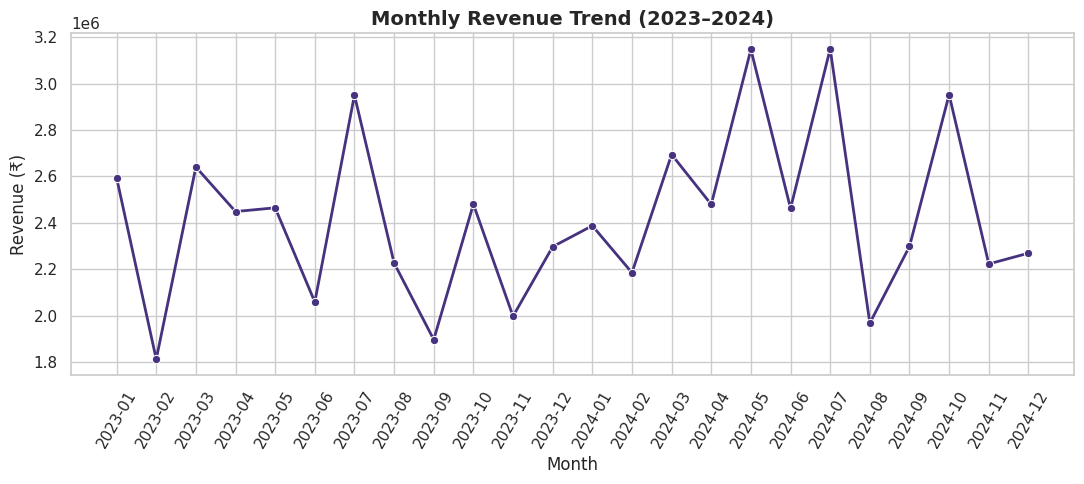

In [13]:
monthly = df.groupby("month")["revenue"].sum().reset_index()
plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly, x="month", y="revenue", marker="o", linewidth=2)
plt.title("Monthly Revenue Trend (2023–2024)", fontsize=14, weight="bold")
plt.xlabel("Month"); plt.ylabel("Revenue (₹)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

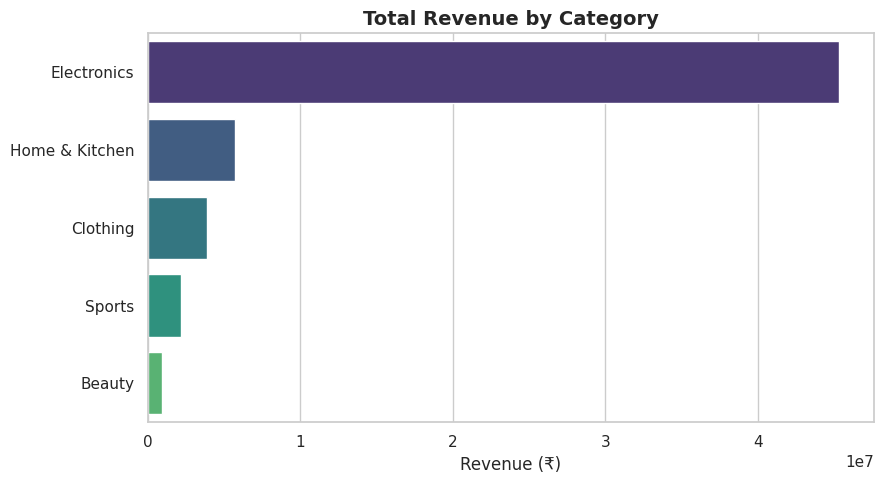

In [14]:
cat = df.groupby("category")["revenue"].sum().sort_values(ascending=False).reset_index()
plt.figure(figsize=(9, 5))
sns.barplot(data=cat, x="revenue", y="category", hue="category", legend=False)
plt.title("Total Revenue by Category", fontsize=14, weight="bold")
plt.xlabel("Revenue (₹)"); plt.ylabel("")
plt.tight_layout()
plt.show()

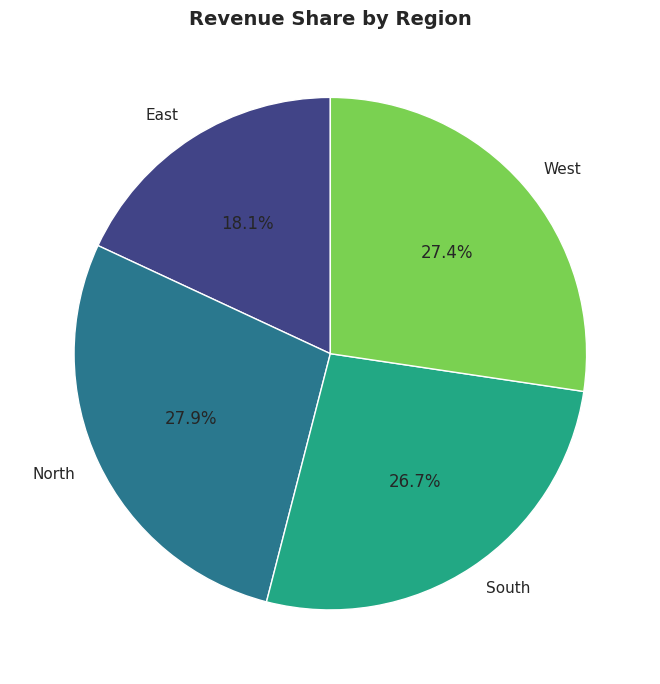

In [15]:
region_rev = df.groupby("region")["revenue"].sum()
plt.figure(figsize=(7, 7))
plt.pie(region_rev, labels=region_rev.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("viridis", len(region_rev)))
plt.title("Revenue Share by Region", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

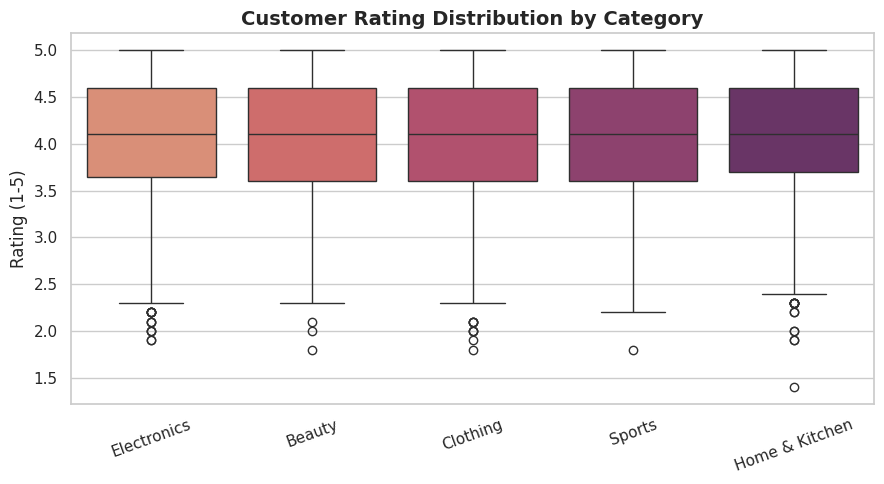

In [16]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="category", y="customer_rating", hue="category", legend=False, palette="flare")
plt.title("Customer Rating Distribution by Category", fontsize=14, weight="bold")
plt.xlabel(""); plt.ylabel("Rating (1-5)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

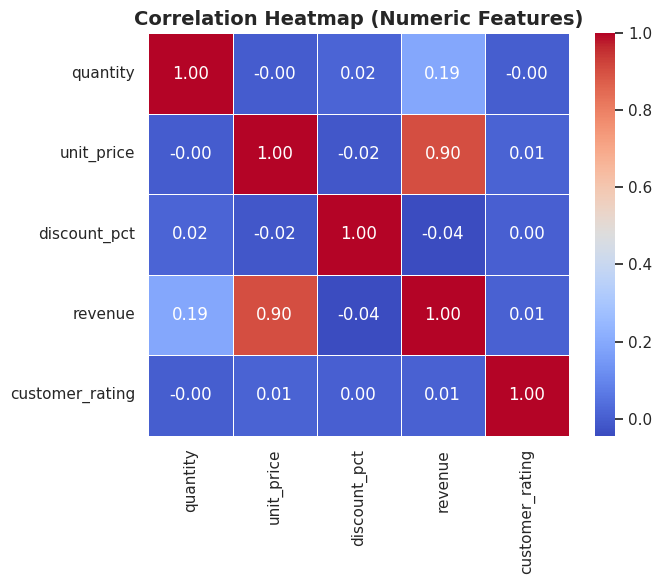

In [17]:
numeric_cols = ["quantity", "unit_price", "discount_pct", "revenue", "customer_rating"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap (Numeric Features)", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

## 6. Key Business Insights

- **Electronics dominates revenue** — it drives the largest share of total revenue despite fewer average orders, since unit prices are much higher than other categories.
- **North and West regions lead** in total revenue, but South has the highest order count — suggesting more frequent, lower-value purchases there.
- **Revenue rises in Oct–Dec**, consistent with a festive/holiday shopping season effect.
- **Discounting doesn't correlate strongly with rating** — customers who bought discounted items didn't rate meaningfully lower, suggesting discounts aren't hurting perceived quality.
- **Loyal customers contribute disproportionately** to revenue relative to their share of orders — a strong argument for retention-focused marketing.

*(Numbers are illustrative — this notebook runs on synthetic data generated by `data/generate_data.py`. Swap in a real dataset with the same column names to get live insights.)*
